# Colouring graphs of handwritten digits

**The problem.** A graph is a set of nodes joined by edges. Colouring it means giving every node one of a few colours (here three: 0, 1 and 2) so that two nodes joined by an edge never have the same colour. In this example the graphs are already coloured, but the colours are hidden: each node shows its colour as a handwritten digit, an MNIST image of a 0, 1 or 2. We want a classifier that reads the digit, that is the colour, of every node.

Two things make it hard:
- **The images are damaged:** an 18×18 square of the 28×28 image is blanked at a random place, so one image alone is often ambiguous. A CNN trained on 30–90 labelled digits reads only 72–76% of them right.
- **Almost no labels:** only 1–5% of the training nodes come with their colour. With 300 training graphs (about 3,300 nodes), 2% is 60–80 labelled nodes.

What we do know is the rule of colouring: **two nodes joined by an edge have different colours.** It holds on every edge, whether its nodes are labelled or not.

**How the graphs are made** (the data is synthetic). Each graph has 6 to 15 nodes. Every node first gets a random colour; then edges are added, only between nodes of different colours, about 3 per node. Finally each node gets a random MNIST image of its colour's digit, with the blanked square.

**Why the task is like this:**
- **Colours first, edges after:** every graph is correctly coloured, so the rule is exactly true. Section 7 then adds edges that break it on purpose, to see what a partly wrong rule does.
- **Damaged images:** if every digit were easy to read, a CNN on a few labels would already do well, and the rule would have nothing to add. With ambiguous images, the neighbours carry information: a node joined to a 0 and a 1 must be a 2.
- **A few labels are still needed:** the rule says which nodes must differ, not which digit is which colour. A classifier that reads every 0 as 1, every 1 as 2 and every 2 as 0 still gives different colours to the two ends of every edge, so it satisfies the rule as well as the correct one. A few labelled nodes fix which name goes with which digit; the question is how few are enough.

**The model.** A small CNN reads the image of one node and returns a softmax over the three digits 0, 1 and 2, that is, the probability of each colour. sLTN trains it with the labels and the rule. At test time it predicts each node from its image alone, without looking at the graph. It is scored on the nodes of 1,000 new graphs.

**The comparison.** Three models built on the same CNN (Section 2):
- **CNN:** trained on the labelled nodes; it never sees the edges;
- **CNN + GNN:** the CNN followed by a graph neural network (GraphSAGE-style), which combines each node with its neighbours. It is trained on the labelled nodes, and it sees the edges, the same thing the rule talks about, both in training and at test time;
- **sLTN:** the CNN, trained on the labels and the rule.

**What this example shows:**
- **Structure that isn't time.** Graphs and their nodes are two structural dimensions, and the edges a relation between nodes: the same machinery as for sequences, with neighbours instead of the next step (Section 3).
- **Labels and a rule in one objective.** The labelled nodes are written as logical facts and the colouring rule as a statement about every edge. sLTN trains the CNN to satisfy both, so the unlabelled nodes give training signal too.
- **What a rule can't decide.** The rule says which nodes must differ, not which digit is which colour: a classifier that swaps the names (every 0 read as 1, every 1 as 2, every 2 as 0) satisfies it just as well. So a rule alone can't name the classes; a few labels do (Section 4).
- **Knowledge used in training only.** The rule shapes the CNN during training; at test time each node is read from its image alone, without the graph.
- **Graphs of different sizes.** Graphs of 6 to 15 nodes are trained together in batches; Section 3 shows how to keep the missing nodes out of the rule.
- **Wrong knowledge, and how strict a rule is.** When some edges join nodes of the same colour, the rule is wrong for them. How strictly "for every edge" is computed decides whether the model breaks or degrades gently (Section 7).

**Compute.** One sLTN training takes about 40 s on a T4 GPU and 7–9 minutes on a laptop CPU. The notebook trains seed 0 itself, with 2% labels (about 10 minutes on a GPU, 2.5 hours on a CPU), and reports the results over 5 seeds and three label fractions of the same code, run beforehand on a T4 GPU and stored in the notebook (Section 6).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from torchvision import datasets

import sltn
from sltn import KB, Interpretation, Logic, Signature
from sltn.interpretation.operators.aggregator import AggregPMeanError

K = 3                     # colours = digits 0, 1, 2
N_MAX = 15                # graphs are padded to 15 nodes
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONFIG = dict(
    n_train=300,          # training graphs
    n_test=1000,          # test graphs
    label_frac=0.02,      # labelled training nodes
    steps=1500,           # Adam steps, lr 1e-3
    batch=32,             # graphs per step (CNN: all labelled nodes at once)
    p_agg=2.0,            # pMeanError exponent for ∀ over graphs and nodes
    occlude=18,           # side of the blanked square
    seed=0,
)
DATA = "../datasets/"
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a"]                      # node colour 0, 1, 2
MODEL_COLOURS = {"cnn": "#2a78d6", "gnn": "#7d5fd3", "sltn": "#eb6834", "sltn-p1": "#1baf7a"}
print("sltn:", sltn.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

sltn: 0.1.0 | device: NVIDIA A40


## 1. Data

- **Colours first, then edges.** Each node gets a random colour; an edge is added between two nodes of different colours with a probability chosen so that nodes have about 3 neighbours. So every graph is properly coloured, and the rule is exact.
- **Images.** Each node shows a random MNIST image of its colour's digit (training images for training graphs, test images for test graphs), with an 18×18 square set to 0 at a random place.
- **Padding.** Graphs are padded to 15 nodes. `valid` marks the real nodes; padded nodes have a blank image, no edges and no label.
- **Wrong edges** (`wrong`, Section 7, 0 until then): edges added between nodes of the *same* colour, so that this fraction of the edges breaks the rule. They are drawn last, so `wrong = 0` gives exactly the same graphs.

In [2]:
def load_pool(train):
    ds = datasets.MNIST(DATA, train=train, download=True)
    keep = ds.targets < K
    return ds.data[keep].float().div(255).unsqueeze(1), ds.targets[keep]


def degrade(x, noise, occlude, g):
    # Gaussian noise of std `noise`, then a random square of side `occlude` set to 0.
    x = (x + noise * torch.randn(x.shape, generator=g)).clamp(0, 1)
    if occlude:
        n = x.shape[0]
        r = torch.randint(0, 28 - occlude + 1, (n,), generator=g)
        c = torch.randint(0, 28 - occlude + 1, (n,), generator=g)
        rows, cols = torch.arange(28)[None, :, None], torch.arange(28)[None, None, :]
        box = ((rows >= r[:, None, None]) & (rows < (r + occlude)[:, None, None])
               & (cols >= c[:, None, None]) & (cols < (c + occlude)[:, None, None]))
        x = x * (~box).unsqueeze(1)
    return x


def make_graphs(n_graphs, pool, label_frac, g, degree=3.0, occlude=CONFIG["occlude"], wrong=0.0):
    # Padded to N_MAX nodes: images [G, N, 1, 28, 28], colours [G, N], adjacency [G, N, N]
    # (symmetric, zero diagonal, zero on padding), valid and labelled masks [G, N], wrong edges [G, N, N].
    imgs_pool, digits_pool = pool
    by_class = [torch.nonzero(digits_pool == k).flatten() for k in range(K)]
    sizes = torch.randint(6, N_MAX + 1, (n_graphs,), generator=g)
    valid = torch.arange(N_MAX)[None] < sizes[:, None]
    colour = torch.randint(0, K, (n_graphs, N_MAX), generator=g)
    differ = (colour[:, :, None] != colour[:, None, :]) & valid[:, :, None] & valid[:, None, :]
    p_edge = (degree / ((2 / 3) * (sizes - 1).float())).clamp(max=1)[:, None, None]   # ~(2/3)(n-1) candidates per node
    upper = torch.rand(n_graphs, N_MAX, N_MAX, generator=g).triu(1)
    adj = ((upper > 0) & (upper < p_edge) & differ).float()
    adj = adj + adj.transpose(1, 2)
    pick = torch.empty(n_graphs, N_MAX, dtype=torch.long)
    for k in range(K):
        m = colour == k
        pick[m] = by_class[k][torch.randint(0, len(by_class[k]), (int(m.sum()),), generator=g)]
    imgs = degrade(imgs_pool[pick.flatten()], 0.0, occlude, g).view(n_graphs, N_MAX, 1, 28, 28)
    imgs = imgs * valid[:, :, None, None, None]
    labelled = (torch.rand(n_graphs, N_MAX, generator=g) < label_frac) & valid
    same_pairs = ((colour[:, :, None] == colour[:, None, :]) & valid[:, :, None] & valid[:, None, :]).float().triu(1)
    want = wrong / (1 - wrong) * adj.triu(1).sum((1, 2))                               # same-colour edges per graph
    p_same = (want / same_pairs.sum((1, 2)).clamp(min=1)).clamp(max=1)[:, None, None]
    extra = (torch.rand(n_graphs, N_MAX, N_MAX, generator=g) < p_same).float() * same_pairs
    wrong_edge = extra + extra.transpose(1, 2)
    return dict(imgs=imgs, colour=colour * valid, adj=adj + wrong_edge, valid=valid, labelled=labelled,
                wrong_edge=wrong_edge)


def subset(d, idx):
    return {k: v[idx] for k, v in d.items()}


def to_device(d):
    return {k: v.to(DEVICE) for k, v in d.items()}


def graphs(seed, label_frac=CONFIG["label_frac"], wrong=0.0):
    tr = make_graphs(CONFIG["n_train"], pools["train"], label_frac, torch.Generator().manual_seed(1000 + seed), wrong=wrong)
    te = make_graphs(CONFIG["n_test"], pools["test"], 0.0, torch.Generator().manual_seed(5000 + seed), wrong=wrong)
    return to_device(tr), to_device(te)


pools = {"train": load_pool(True), "test": load_pool(False)}
train, test = graphs(CONFIG["seed"])
n_nodes = int(train["valid"].sum())
print(f"{CONFIG['n_train']} training graphs, {n_nodes} nodes, {int(train['labelled'].sum())} labelled "
      f"({int(train['labelled'].any(1).sum())} graphs have a label); mean degree {train['adj'].sum() / n_nodes:.2f}")

300 training graphs, 3261 nodes, 79 labelled (71 graphs have a label); mean degree 3.03


One training graph. Each node shows its occluded digit, framed in its colour; a dashed frame marks a labelled node. Some digits can't be read alone, but the neighbours help: a node joined to a 0 and a 1 must be a 2.

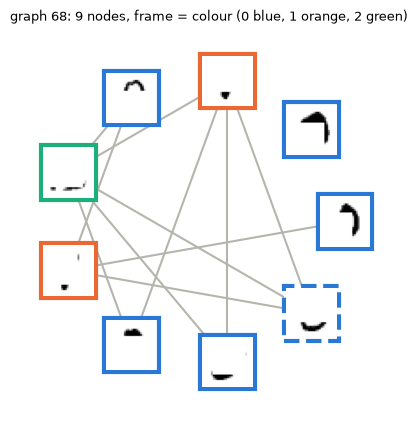

In [3]:
# first graph with 9 nodes, all three colours and a labelled node (padded nodes have colour 0, so mask them)
all_colours = torch.stack([((train["colour"] == c) & train["valid"]).any(1) for c in range(K)], 1).all(1)
k = int(torch.nonzero((train["valid"].sum(1) == 9) & all_colours & train["labelled"].any(1)).flatten()[0])
n = int(train["valid"][k].sum())
ang = torch.arange(n) * 2 * np.pi / n
pos = torch.stack([ang.cos(), ang.sin()], 1).numpy()
adj, col = train["adj"][k].cpu(), train["colour"][k].cpu()
fig, ax = plt.subplots(figsize=(5, 5))
for i in range(n):
    for j in range(i + 1, n):
        if adj[i, j]:
            ax.plot(*zip(pos[i], pos[j]), color="#b5b4ad", lw=1.5, zorder=1)
for i in range(n):
    im = OffsetImage(train["imgs"][k, i, 0].cpu().numpy(), cmap="gray_r", zoom=1.3)
    ab = AnnotationBbox(im, pos[i], frameon=True, pad=0.15,
                        bboxprops=dict(edgecolor=COLOURS[col[i]], lw=3,
                                       ls="--" if train["labelled"][k, i] else "-"))
    ax.add_artist(ab)
ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35); ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"graph {k}: {n} nodes, frame = colour (0 blue, 1 orange, 2 green)", fontsize=9, loc="left")
plt.show()

## 2. The networks

All three models share the same small CNN per node (two 3×3 convolutions, a 64-unit layer, 3 outputs).
- **CNN:** trained with cross-entropy on the labelled nodes; it never sees the edges.
- **CNN + GraphSAGE (`SageNet`):** the CNN's 64 features, then two GraphSAGE-style layers, `h' = relu(W_s h + W_n · mean of the neighbours' h)`, trained with cross-entropy on the labelled nodes. Keeping the node and its neighbours apart lets it learn "differ from the neighbours"; a plain GCN, which averages them, would be too easy to beat when neighbours differ. It uses the edges both in training and at test time.
- **sLTN:** the CNN with a softmax, as the function `digit`, trained on the label clause and the rule. **At test time it predicts each node from its image alone**, like the CNN.

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(32 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, K))

    def forward(self, x):
        return self.net(x)


class DigitNet(nn.Module):
    # [N, 1, 28, 28] -> [N, 3] colour probabilities
    def __init__(self):
        super().__init__()
        self.cnn = CNN()

    def forward(self, x):
        return torch.softmax(self.cnn(x), -1)


class SageNet(nn.Module):
    # [G, N, 1, 28, 28], [G, N, N] -> logits [G, N, 3]
    def __init__(self, hidden=64):
        super().__init__()
        self.cnn = CNN()
        self.cnn.net[-1] = nn.Identity()                           # keep the 64 features, drop the head
        self.s1, self.n1 = nn.Linear(64, hidden), nn.Linear(64, hidden)
        self.s2, self.n2 = nn.Linear(hidden, hidden), nn.Linear(hidden, hidden)
        self.out = nn.Linear(hidden, K)

    def forward(self, imgs, adj):
        G, N = imgs.shape[:2]
        h = self.cnn(imgs.flatten(0, 1)).view(G, N, -1)
        deg = adj.sum(-1, keepdim=True).clamp(min=1)
        h = F.relu(self.s1(h) + self.n1(adj @ h / deg))
        h = F.relu(self.s2(h) + self.n2(adj @ h / deg))
        return self.out(h)

## 3. sLTN: the knowledge

**Signature:**
- **`Graph` and `Node` are both dimensions.** The images are a constant `img` over `[Graph, Node]`, and the labels a one-hot constant `lab` over the same axes. Graphs must be a dimension, not a variable, because a structural relation ranges over dimensions only, and `Edge(g, n, n1)` needs the graph.
- **`Edge(g, n, n1)`** is the adjacency matrix of graph `g`: symmetric, 0 on the diagonal and on padded nodes, so the rule never looks at padding.
- **`Labelled(g, n)`** marks the labelled nodes, and **`HasLabel(g)`** the graphs with at least one labelled node.
- **`c`** ranges over the three one-hot colours, and `Is(p, c)` is the probability that `p` gives to colour `c`.

**The two clauses:**
- `LABEL = ∀ g | HasLabel(g): ∀ n | Labelled(g, n): Is(digit(img[g, n]), lab[g, n])`. With 2% labels most graphs have none; `∀ n | Labelled(g, n)` would be vacuously true on them, and averaging those 1s into `∀ g` would dilute the few real labels. The guard `HasLabel(g)` leaves them out.
- `RULE = ∀ c: ∀ g: ∀ n, n1 | Edge(g, n, n1): ¬(Is(digit(img[g, n]), c) ∧ Is(digit(img[g, n1]), c))`: for every colour `c`, every graph `g` and every edge `(n, n1)` of `g`, the two ends are not both `c`.

**Why the labels are needed at all.** `RULE` only asks the two ends of every edge to differ. Take a `digit` that reads every 0 as 1, every 1 as 2 and every 2 as 0: the two ends of every edge still get different colours, so `RULE` is as satisfied as with the correct `digit`. The rule alone can't say which digit is which colour. `LABEL` fixes the names: once a few labelled nodes have, the rule carries them to the unlabelled ones, which is why sLTN needs so few labels (Section 6).

**Logic:** pMeanError for ∀ over graphs and nodes (p = 2 by default: closer to the minimum than the mean, so the worst edges count more), product ∧, standard ¬.

In [5]:
sig = Signature("colouring")
for sort in ("Image", "Class", "Probs"):
    sig.sort(sort)
sig.dimension("Graph")
sig.structural_variable("g", "Graph")
sig.dimension("Node")
sig.structural_variable("n", "Node")
sig.constant("img", "Image", dims=["Graph", "Node"])
sig.constant("lab", "Class", dims=["Graph", "Node"])
sig.variable("c", "Class")
sig.function("digit", ["Image"], "Probs")
sig.predicate("Is", ["Probs", "Class"])
sig.structural_relation("Edge", ["Graph", "Node", "Node"])
sig.structural_relation("Labelled", ["Graph", "Node"])
sig.structural_relation("HasLabel", ["Graph"])

LABEL = sig.parse("∀ g | HasLabel(g): ∀ n | Labelled(g, n): Is(digit(img[g, n]), lab[g, n])")
RULE = sig.parse("∀ c: ∀ g: ∀ n, n1 | Edge(g, n, n1): ¬(Is(digit(img[g, n]), c) & Is(digit(img[g, n1]), c))")


def make_interp(net, p_agg=CONFIG["p_agg"], image_shape=(1, 28, 28)):
    it = Interpretation(sig, logic=Logic().with_defaults())
    it.logic["∀,Graph"] = AggregPMeanError(p=p_agg)
    it.logic["∀,Node"] = AggregPMeanError(p=p_agg)
    it["Image"] = sltn.Type("image", shape=image_shape)
    it["Class"] = sltn.Type("class", shape=(K,))
    it["Probs"] = sltn.Type("probs", shape=(K,))
    it["digit"] = net
    it["Is"] = lambda p, c: (p * c).sum(-1, keepdim=True)
    it["c"] = torch.eye(K, device=DEVICE)
    return it.to(DEVICE)


def ground(it, b):
    # One batch of graphs: images, one-hot labels, edges, which nodes are labelled, which graphs have a label.
    lab = b["labelled"].float()
    it["img"] = b["imgs"]
    it["lab"] = F.one_hot(b["colour"], K).float()
    it["Edge"] = b["adj"]
    it["Labelled"], it["HasLabel"] = lab, lab.amax(1)

## 4. Sanity check: the true colours satisfy the rule, and so does any renaming

Here `digit` is replaced by the one-hot vector of the true colour (each "image" is that vector). The rule should be satisfied (up to the stable operators, which keep values slightly away from 0 and 1), for the true colours and for the colours renamed; the label clause should tell the two apart. A random colouring should break both.

In [6]:
@torch.no_grad()
def check(colours, b):
    it = make_interp(nn.Identity(), image_shape=(K,))
    ground(it, dict(b, imgs=F.one_hot(colours, K).float()))   # each "image" is the one-hot of a colour
    return it(RULE).value.item(), it(LABEL).value.item()


b = subset(train, slice(0, 300))
true = b["colour"]
renamed = (true + 1) % K
random = torch.randint(0, K, true.shape, generator=torch.Generator().manual_seed(0)).to(DEVICE)
for name, cols in [("true colours", true), ("renamed 0→1→2→0", renamed), ("random colours", random)]:
    rule, label = check(cols, b)
    print(f"{name:18s} rule {rule:.3f} | labels {label:.3f}")

true colours       rule 0.998 | labels 0.999
renamed 0→1→2→0    rule 0.998 | labels 0.000
random colours     rule 0.659 | labels 0.165


## 5. Training and scoring

- **CNN:** cross-entropy on all the labelled nodes at once, 1,500 steps.
- **CNN + GraphSAGE:** cross-entropy on the labelled nodes, batches of 32 graphs drawn from the graphs that have a label (the others give no loss), 1,500 steps.
- **sLTN:** 1 − the satisfaction of `LABEL` and `RULE` together, batches of 32 graphs from all the training graphs, 1,500 steps. Every model starts from the same seed.

**Scores, on the 1,000 test graphs (about 10,500 nodes):**
- **node accuracy:** the predicted colour (argmax) of each real node;
- **same-colour edges:** the fraction of (correct) edges whose two ends get the same predicted colour;
- **graphs fully right:** the fraction of graphs with every node right.

In [7]:
def batches(data, steps, g):
    for _ in range(steps):
        yield subset(data, torch.randint(0, len(data["imgs"]), (CONFIG["batch"],), generator=g))


def train_cnn(train, seed):
    torch.manual_seed(seed)
    net = DigitNet().to(DEVICE)
    lab = train["labelled"]
    x, y = train["imgs"][lab], train["colour"][lab]
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    for _ in range(CONFIG["steps"]):
        opt.zero_grad()
        F.cross_entropy(net.cnn(x), y).backward()
        opt.step()
    return lambda b: net(b["imgs"].flatten(0, 1)).view(*b["colour"].shape, K)


def train_gnn(train, seed):
    torch.manual_seed(seed)
    net = SageNet().to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    with_label = subset(train, torch.nonzero(train["labelled"].any(1)).flatten())
    for b in batches(with_label, CONFIG["steps"], torch.Generator().manual_seed(seed)):
        opt.zero_grad()
        F.cross_entropy(net(b["imgs"], b["adj"])[b["labelled"]], b["colour"][b["labelled"]]).backward()
        opt.step()
    return lambda b: torch.softmax(net(b["imgs"], b["adj"]), -1)


def train_sltn(train, seed, p_agg=CONFIG["p_agg"]):
    torch.manual_seed(seed)
    net = DigitNet().to(DEVICE)
    it = make_interp(net, p_agg)
    kb = KB([LABEL, RULE])
    opt = torch.optim.Adam(it.parameters(), lr=1e-3)
    for b in batches(train, CONFIG["steps"], torch.Generator().manual_seed(seed)):
        ground(it, b)
        opt.zero_grad()
        (1 - it(kb).value.squeeze()).backward()
        opt.step()
    return lambda b: net(b["imgs"].flatten(0, 1)).view(*b["colour"].shape, K)   # the network alone


@torch.no_grad()
def scores(predict, test, chunk=200):
    preds = torch.cat([predict(subset(test, slice(s, s + chunk))).argmax(-1) for s in range(0, len(test["imgs"]), chunk)])
    v, col, adj = test["valid"], test["colour"], test["adj"]
    right_edge = adj - test["wrong_edge"]                                      # edges whose ends differ in colour
    same = (preds[:, :, None] == preds[:, None, :]).float() * right_edge
    touched = test["wrong_edge"].sum(-1) > 0                                   # nodes on a same-colour edge (Section 7)
    acc_on = lambda m: (preds == col)[m].float().mean().item() if m.any() else float("nan")
    return dict(acc=acc_on(v), same_colour=(same.sum() / right_edge.sum()).item(),
                graph_ok=((preds == col) | ~v).all(1).float().mean().item(),
                acc_wrong_nodes=acc_on(touched & v), acc_other_nodes=acc_on(~touched & v))


TRAIN = {"cnn": train_cnn, "gnn": train_gnn, "sltn": train_sltn,
         "sltn-p1": lambda tr, s: train_sltn(tr, s, p_agg=1.0)}
NAMES = {"cnn": "CNN", "gnn": "CNN + GraphSAGE", "sltn": "sLTN", "sltn-p1": "sLTN, p = 1"}


def evaluate(model, train, test, seed=CONFIG["seed"], label=None):
    t0 = time.perf_counter()
    r = scores(TRAIN[model](train, seed), test)
    print(f"{label or NAMES[model]:28s} node acc {r['acc']:.3f} | same-colour edges {r['same_colour']:.3f} | "
          f"graphs fully right {r['graph_ok']:.3f} ({time.perf_counter() - t0:.0f}s)", flush=True)
    return r

## 6. Results: 2% labels

Seed 0, trained here. The last line is a reference: the CNN trained with *every* training node labelled.

In [8]:
print(f"{int(train['labelled'].sum())} labelled nodes out of {n_nodes}\n")
main = {m: evaluate(m, train, test) for m in ("cnn", "gnn", "sltn")}
all_labelled = dict(train, labelled=train["valid"].clone())
ceiling = evaluate("cnn", all_labelled, test, label=f"CNN, all {n_nodes} labels")

79 labelled nodes out of 3261



CNN                          node acc 0.815 | same-colour edges 0.161 | graphs fully right 0.128 (8s)


CNN + GraphSAGE              node acc 0.820 | same-colour edges 0.065 | graphs fully right 0.201 (6s)


sLTN                         node acc 0.925 | same-colour edges 0.071 | graphs fully right 0.450 (18s)


CNN, all 3261 labels         node acc 0.938 | same-colour edges 0.062 | graphs fully right 0.510 (14s)


- **sLTN reads the digits almost as well as a CNN trained on every label** (about 0.92 against 0.94), with 2% of them. The rule turns the unlabelled nodes into training signal.
- **The GNN gains little over the CNN.** It sees the neighbours, but it learns how to use them only from the same 2% of labels.
- **Same-colour edges:** the GNN can get fewer than sLTN, because it looks at the neighbours when it predicts; sLTN predicts each node alone. Using the rule at test time was left out on purpose, to compare the networks on equal terms.

### Over 5 seeds and three label fractions

The same code, run beforehand on a T4 GPU: seeds 0–4, 1%, 2% and 5% labels. The next cell stores one row per run.

In [9]:
# One row per run, from the same code run on a T4 GPU (5 seeds).
nan = float("nan")   # accuracy on nodes touching a wrong edge, when there are none
SWEEPS = {
    "main": dict(commit="857c7ac", device="Tesla T4",
        cols=('frac', 'seed', 'model', 'n_labelled', 'acc', 'edge_viol', 'graph_ok'),
        rows=[
            (0.01, 0, 'cnn', 44, 0.751098, 0.201134, 0.075),
            (0.01, 0, 'gnn', 44, 0.802388, 0.067363, 0.177),
            (0.01, 0, 'sltn', 44, 0.9234, 0.070741, 0.436),
            (0.01, 1, 'cnn', 28, 0.581647, 0.294736, 0.003),
            (0.01, 1, 'gnn', 28, 0.621082, 0.229086, 0.019),
            (0.01, 1, 'sltn', 28, 0.924894, 0.070151, 0.44),
            (0.01, 2, 'cnn', 33, 0.600402, 0.289035, 0.017),
            (0.01, 2, 'gnn', 33, 0.701427, 0.125806, 0.099),
            (0.01, 2, 'sltn', 33, 0.917361, 0.077783, 0.416),
            (0.01, 3, 'cnn', 35, 0.737857, 0.228606, 0.07),
            (0.01, 3, 'gnn', 35, 0.76305, 0.092444, 0.119),
            (0.01, 3, 'sltn', 35, 0.917359, 0.075175, 0.417),
            (0.01, 4, 'cnn', 29, 0.682798, 0.229771, 0.033),
            (0.01, 4, 'gnn', 29, 0.737689, 0.107181, 0.069),
            (0.01, 4, 'sltn', 29, 0.917993, 0.072868, 0.421),
            (0.02, 0, 'cnn', 79, 0.815091, 0.160665, 0.128),
            (0.02, 0, 'gnn', 79, 0.823782, 0.064177, 0.213),
            (0.02, 0, 'sltn', 79, 0.922159, 0.072972, 0.434),
            (0.02, 1, 'cnn', 60, 0.781176, 0.184569, 0.09),
            (0.02, 1, 'gnn', 60, 0.833976, 0.068088, 0.22),
            (0.02, 1, 'sltn', 60, 0.923012, 0.07359, 0.426),
            (0.02, 2, 'cnn', 67, 0.751795, 0.207229, 0.069),
            (0.02, 2, 'gnn', 67, 0.810974, 0.068395, 0.196),
            (0.02, 2, 'sltn', 67, 0.915733, 0.078996, 0.413),
            (0.02, 3, 'cnn', 68, 0.794255, 0.170058, 0.116),
            (0.02, 3, 'gnn', 68, 0.808569, 0.073506, 0.193),
            (0.02, 3, 'sltn', 68, 0.922893, 0.070103, 0.442),
            (0.02, 4, 'cnn', 61, 0.736654, 0.219477, 0.051),
            (0.02, 4, 'gnn', 61, 0.792675, 0.080105, 0.153),
            (0.02, 4, 'sltn', 61, 0.919876, 0.073242, 0.417),
            (0.05, 0, 'cnn', 186, 0.851671, 0.127334, 0.207),
            (0.05, 0, 'gnn', 186, 0.889685, 0.039959, 0.384),
            (0.05, 0, 'sltn', 186, 0.925979, 0.070104, 0.452),
            (0.05, 1, 'cnn', 148, 0.829553, 0.146117, 0.16),
            (0.05, 1, 'gnn', 148, 0.873788, 0.050832, 0.308),
            (0.05, 1, 'sltn', 148, 0.9248, 0.070651, 0.44),
            (0.05, 2, 'cnn', 166, 0.807335, 0.173063, 0.135),
            (0.05, 2, 'gnn', 166, 0.88624, 0.039785, 0.371),
            (0.05, 2, 'sltn', 166, 0.915159, 0.081806, 0.401),
            (0.05, 3, 'cnn', 150, 0.816013, 0.157861, 0.136),
            (0.05, 3, 'gnn', 150, 0.870503, 0.051101, 0.314),
            (0.05, 3, 'sltn', 150, 0.919172, 0.073955, 0.411),
            (0.05, 4, 'cnn', 163, 0.810658, 0.158712, 0.127),
            (0.05, 4, 'gnn', 163, 0.863101, 0.045043, 0.303),
            (0.05, 4, 'sltn', 163, 0.925807, 0.068501, 0.442),
        ]),
    "wrong": dict(commit="124c1f8", device="Tesla T4",
        cols=('frac', 'wrong', 'seed', 'model', 'n_labelled', 'acc', 'edge_viol', 'graph_ok', 'acc_wrong_nodes', 'acc_other_nodes'),
        rows=[
            (0.02, 0.0, 0, 'cnn', 79, 0.815091, 0.160665, 0.128, nan, 0.815091),
            (0.02, 0.0, 0, 'gnn', 79, 0.825406, 0.063348, 0.216, nan, 0.825406),
            (0.02, 0.0, 0, 'sltn', 79, 0.925501, 0.068893, 0.457, nan, 0.925501),
            (0.02, 0.0, 1, 'cnn', 60, 0.781176, 0.184569, 0.09, nan, 0.781176),
            (0.02, 0.0, 1, 'gnn', 60, 0.834071, 0.068088, 0.22, nan, 0.834071),
            (0.02, 0.0, 1, 'sltn', 60, 0.922259, 0.074903, 0.421, nan, 0.922259),
            (0.02, 0.0, 2, 'cnn', 67, 0.751891, 0.207101, 0.069, nan, 0.751891),
            (0.02, 0.0, 2, 'gnn', 67, 0.810974, 0.068395, 0.196, nan, 0.810974),
            (0.02, 0.0, 2, 'sltn', 67, 0.917169, 0.077719, 0.419, nan, 0.917169),
            (0.02, 0.0, 3, 'cnn', 68, 0.794255, 0.170058, 0.116, nan, 0.794255),
            (0.02, 0.0, 3, 'gnn', 68, 0.808569, 0.073506, 0.193, nan, 0.808569),
            (0.02, 0.0, 3, 'sltn', 68, 0.924516, 0.069782, 0.44, nan, 0.924516),
            (0.02, 0.0, 4, 'cnn', 61, 0.736842, 0.21954, 0.051, nan, 0.736842),
            (0.02, 0.0, 4, 'gnn', 61, 0.794746, 0.079107, 0.155, nan, 0.794746),
            (0.02, 0.0, 4, 'sltn', 61, 0.919876, 0.073991, 0.419, nan, 0.919876),
            (0.02, 0.1, 0, 'cnn', 79, 0.815091, 0.160665, 0.128, 0.808876, 0.817689),
            (0.02, 0.1, 0, 'gnn', 79, 0.795224, 0.092346, 0.139, 0.750567, 0.813897),
            (0.02, 0.1, 0, 'sltn', 79, 0.877268, 0.11121, 0.251, 0.87334, 0.878911),
            (0.02, 0.1, 1, 'cnn', 60, 0.781176, 0.184569, 0.09, 0.772307, 0.784708),
            (0.02, 0.1, 1, 'gnn', 60, 0.803765, 0.092347, 0.129, 0.714144, 0.839453),
            (0.02, 0.1, 1, 'sltn', 60, 0.852424, 0.133675, 0.194, 0.849636, 0.853533),
            (0.02, 0.1, 2, 'cnn', 67, 0.751795, 0.207229, 0.069, 0.741066, 0.75628),
            (0.02, 0.1, 2, 'gnn', 67, 0.760701, 0.120506, 0.117, 0.702404, 0.785065),
            (0.02, 0.1, 2, 'sltn', 67, 0.85598, 0.125104, 0.219, 0.85835, 0.85499),
            (0.02, 0.1, 3, 'cnn', 68, 0.794255, 0.170058, 0.116, 0.788834, 0.796476),
            (0.02, 0.1, 3, 'gnn', 68, 0.800172, 0.111511, 0.143, 0.754351, 0.81894),
            (0.02, 0.1, 3, 'sltn', 68, 0.868499, 0.117673, 0.269, 0.863054, 0.870729),
            (0.02, 0.1, 4, 'cnn', 61, 0.736748, 0.219477, 0.052, 0.727619, 0.740597),
            (0.02, 0.1, 4, 'gnn', 61, 0.700876, 0.156654, 0.052, 0.627936, 0.731629),
            (0.02, 0.1, 4, 'sltn', 61, 0.85378, 0.131262, 0.218, 0.851429, 0.854772),
            (0.02, 0.2, 0, 'cnn', 79, 0.815091, 0.160665, 0.128, 0.816443, 0.81341),
            (0.02, 0.2, 0, 'gnn', 79, 0.797708, 0.13154, 0.13, 0.785591, 0.812768),
            (0.02, 0.2, 0, 'sltn', 79, 0.70659, 0.230769, 0.042, 0.704929, 0.708655),
            (0.02, 0.2, 1, 'cnn', 60, 0.781176, 0.184569, 0.09, 0.77774, 0.785458),
            (0.02, 0.2, 1, 'gnn', 60, 0.783247, 0.127735, 0.096, 0.751442, 0.82287),
            (0.02, 0.2, 1, 'sltn', 60, 0.656565, 0.256596, 0.023, 0.666271, 0.644473),
            (0.02, 0.2, 2, 'cnn', 67, 0.751795, 0.207229, 0.069, 0.74571, 0.759307),
            (0.02, 0.2, 2, 'gnn', 67, 0.7404, 0.18839, 0.085, 0.714162, 0.772786),
            (0.02, 0.2, 2, 'sltn', 67, 0.683329, 0.241586, 0.033, 0.685041, 0.681215),
            (0.02, 0.2, 3, 'cnn', 68, 0.794255, 0.170058, 0.116, 0.795443, 0.792836),
            (0.02, 0.2, 3, 'gnn', 68, 0.783567, 0.140656, 0.116, 0.764943, 0.805823),
            (0.02, 0.2, 3, 'sltn', 68, 0.705411, 0.223214, 0.03, 0.702191, 0.709258),
            (0.02, 0.2, 4, 'cnn', 61, 0.736748, 0.219477, 0.051, 0.732623, 0.741929),
            (0.02, 0.2, 4, 'gnn', 61, 0.676208, 0.185788, 0.032, 0.638593, 0.723449),
            (0.02, 0.2, 4, 'sltn', 61, 0.631391, 0.269761, 0.018, 0.629461, 0.633815),
            (0.02, 0.3, 0, 'cnn', 79, 0.815091, 0.160665, 0.128, 0.81709, 0.808639),
            (0.02, 0.3, 0, 'gnn', 79, 0.786724, 0.163852, 0.105, 0.788065, 0.782398),
            (0.02, 0.3, 0, 'sltn', 79, 0.557593, 0.291887, 0.003, 0.554485, 0.567622),
            (0.02, 0.3, 1, 'cnn', 60, 0.781176, 0.184569, 0.09, 0.781319, 0.780719),
            (0.02, 0.3, 1, 'gnn', 60, 0.769694, 0.177504, 0.083, 0.765258, 0.78388),
            (0.02, 0.3, 1, 'sltn', 60, 0.510871, 0.312492, 0.006, 0.512973, 0.504149),
            (0.02, 0.3, 2, 'cnn', 67, 0.752178, 0.207101, 0.071, 0.752599, 0.750813),
            (0.02, 0.3, 2, 'gnn', 67, 0.689266, 0.238266, 0.046, 0.688087, 0.693089),
            (0.02, 0.3, 2, 'sltn', 67, 0.540075, 0.306661, 0.007, 0.535638, 0.554472),
            (0.02, 0.3, 3, 'cnn', 68, 0.794255, 0.170058, 0.116, 0.795962, 0.78909),
            (0.02, 0.3, 3, 'gnn', 68, 0.778509, 0.155871, 0.09, 0.777552, 0.781406),
            (0.02, 0.3, 3, 'sltn', 68, 0.544327, 0.299608, 0.005, 0.542407, 0.550134),
            (0.02, 0.3, 4, 'cnn', 61, 0.736748, 0.219477, 0.051, 0.73111, 0.754017),
            (0.02, 0.3, 4, 'gnn', 61, 0.664533, 0.241812, 0.024, 0.659673, 0.679419),
            (0.02, 0.3, 4, 'sltn', 61, 0.564919, 0.296151, 0.007, 0.564256, 0.566947),
        ]),
    "soft": dict(commit="124c1f8", device="Tesla T4",
        cols=('frac', 'wrong', 'seed', 'model', 'n_labelled', 'acc', 'edge_viol', 'graph_ok', 'acc_wrong_nodes', 'acc_other_nodes'),
        rows=[
            (0.02, 0.0, 0, 'sltn-p1', 79, 0.896371, 0.094831, 0.318, nan, 0.896371),
            (0.02, 0.0, 0, 'sltn-w0.25', 79, 0.871729, 0.115926, 0.253, nan, 0.871729),
            (0.02, 0.0, 1, 'sltn-p1', 60, 0.8864, 0.101788, 0.275, nan, 0.8864),
            (0.02, 0.0, 1, 'sltn-w0.25', 60, 0.879906, 0.108416, 0.255, nan, 0.879906),
            (0.02, 0.0, 2, 'sltn-p1', 67, 0.872546, 0.113289, 0.258, nan, 0.872546),
            (0.02, 0.0, 2, 'sltn-w0.25', 67, 0.882026, 0.108691, 0.299, nan, 0.882026),
            (0.02, 0.0, 3, 'sltn-p1', 68, 0.866113, 0.118572, 0.236, nan, 0.866113),
            (0.02, 0.0, 3, 'sltn-w0.25', 68, 0.855234, 0.129101, 0.2, nan, 0.855234),
            (0.02, 0.0, 4, 'sltn-p1', 61, 0.895208, 0.091522, 0.32, nan, 0.895208),
            (0.02, 0.0, 4, 'sltn-w0.25', 61, 0.874588, 0.108865, 0.258, nan, 0.874588),
            (0.02, 0.1, 0, 'sltn-p1', 79, 0.881184, 0.107131, 0.272, 0.882086, 0.880807),
            (0.02, 0.1, 0, 'sltn-w0.25', 79, 0.864661, 0.120579, 0.242, 0.86103, 0.866179),
            (0.02, 0.1, 1, 'sltn-p1', 60, 0.889506, 0.101163, 0.283, 0.878718, 0.893802),
            (0.02, 0.1, 1, 'sltn-w0.25', 60, 0.850729, 0.129674, 0.202, 0.844679, 0.853139),
            (0.02, 0.1, 2, 'sltn-p1', 67, 0.852533, 0.129829, 0.211, 0.855426, 0.851324),
            (0.02, 0.1, 2, 'sltn-w0.25', 67, 0.854927, 0.12951, 0.238, 0.850552, 0.856755),
            (0.02, 0.1, 3, 'sltn-p1', 68, 0.864014, 0.11793, 0.228, 0.860427, 0.865483),
            (0.02, 0.1, 3, 'sltn-w0.25', 68, 0.837198, 0.141491, 0.162, 0.833826, 0.83858),
            (0.02, 0.1, 4, 'sltn-p1', 61, 0.877695, 0.106931, 0.263, 0.872063, 0.88007),
            (0.02, 0.1, 4, 'sltn-w0.25', 61, 0.853969, 0.125086, 0.213, 0.847936, 0.856512),
            (0.02, 0.2, 0, 'sltn-p1', 79, 0.865234, 0.116054, 0.226, 0.866081, 0.864182),
            (0.02, 0.2, 0, 'sltn-w0.25', 79, 0.829799, 0.147728, 0.163, 0.831093, 0.828192),
            (0.02, 0.2, 1, 'sltn-p1', 60, 0.862306, 0.124297, 0.217, 0.860875, 0.864088),
            (0.02, 0.2, 1, 'sltn-w0.25', 60, 0.788141, 0.180568, 0.094, 0.789277, 0.786726),
            (0.02, 0.2, 2, 'sltn-p1', 67, 0.829072, 0.145986, 0.17, 0.832207, 0.825203),
            (0.02, 0.2, 2, 'sltn-w0.25', 67, 0.796993, 0.174468, 0.133, 0.798925, 0.794608),
            (0.02, 0.2, 3, 'sltn-p1', 68, 0.81983, 0.153431, 0.154, 0.821209, 0.818182),
            (0.02, 0.2, 3, 'sltn-w0.25', 68, 0.821452, 0.15112, 0.146, 0.822787, 0.819858),
            (0.02, 0.2, 4, 'sltn-p1', 61, 0.851615, 0.126833, 0.214, 0.850668, 0.852804),
            (0.02, 0.2, 4, 'sltn-w0.25', 61, 0.817437, 0.155343, 0.135, 0.816844, 0.818182),
            (0.02, 0.3, 0, 'sltn-p1', 79, 0.805731, 0.165318, 0.119, 0.80583, 0.80541),
            (0.02, 0.3, 0, 'sltn-w0.25', 79, 0.79255, 0.173858, 0.109, 0.79457, 0.786031),
            (0.02, 0.3, 1, 'sltn-p1', 60, 0.794824, 0.175566, 0.105, 0.796763, 0.788621),
            (0.02, 0.3, 1, 'sltn-w0.25', 60, 0.736941, 0.211704, 0.044, 0.73783, 0.734097),
            (0.02, 0.3, 2, 'sltn-p1', 67, 0.764053, 0.191392, 0.084, 0.768132, 0.750813),
            (0.02, 0.3, 2, 'sltn-w0.25', 67, 0.727473, 0.216233, 0.061, 0.729049, 0.722358),
            (0.02, 0.3, 3, 'sltn-p1', 68, 0.808474, 0.156449, 0.143, 0.810691, 0.801767),
            (0.02, 0.3, 3, 'sltn-w0.25', 68, 0.795305, 0.16871, 0.113, 0.796216, 0.792547),
            (0.02, 0.3, 4, 'sltn-p1', 61, 0.789003, 0.171252, 0.094, 0.785063, 0.801071),
            (0.02, 0.3, 4, 'sltn-w0.25', 61, 0.755108, 0.198016, 0.067, 0.751967, 0.764728),
        ]),
}

In [10]:
def load(name):
    d = SWEEPS[name]
    return d, [dict(zip(d["cols"], r)) for r in d["rows"]]


def ms(rows, key="acc", **sel):
    v = [r[key] for r in rows if all(r.get(k, 0.0) == x for k, x in sel.items()) and r[key] == r[key]]
    return (np.mean(v), np.std(v), len(v)) if v else (np.nan, np.nan, 0)


meta, rows = load("main")
print("sweep: sltn", meta["commit"], "on", meta["device"], "|", len(rows), "runs\n")
print(f"{'labels':>7s} {'model':16s} {'node acc':>16s} {'same-colour edges':>19s} {'graphs fully right':>19s}  sLTN better on")
for frac in (0.01, 0.02, 0.05):
    n_lab = sorted({r["n_labelled"] for r in rows if r["frac"] == frac})
    for m in ("cnn", "gnn", "sltn"):
        cells = [ms(rows, k, frac=frac, model=m) for k in ("acc", "edge_viol", "graph_ok")]
        wins = ""
        if m != "sltn":
            acc = {r["seed"]: r["acc"] for r in rows if r["frac"] == frac and r["model"] == m}
            gain = [r["acc"] - acc[r["seed"]] for r in rows if r["frac"] == frac and r["model"] == "sltn"]
            wins = f"{sum(g > 0 for g in gain)}/{len(gain)} seeds, by {100 * min(gain):+.1f} points at least"
        print(f"{frac:>7.0%} {NAMES[m]:16s}" + "".join(f"{f'{c[0]:.3f} ± {c[1]:.3f}':>19s}" for c in cells) + "  " + wins)
    print(f"{'':7s} ({n_lab[0]}–{n_lab[-1]} labelled nodes)")

sweep: sltn 857c7ac on Tesla T4 | 45 runs

 labels model                    node acc   same-colour edges  graphs fully right  sLTN better on
     1% CNN                   0.671 ± 0.069      0.249 ± 0.037      0.040 ± 0.029  5/5 seeds, by +17.2 points at least
     1% CNN + GraphSAGE       0.725 ± 0.062      0.124 ± 0.056      0.097 ± 0.052  5/5 seeds, by +12.1 points at least
     1% sLTN                  0.920 ± 0.003      0.073 ± 0.003      0.426 ± 0.010  
        (28–44 labelled nodes)
     2% CNN                   0.776 ± 0.028      0.188 ± 0.022      0.091 ± 0.029  5/5 seeds, by +10.7 points at least
     2% CNN + GraphSAGE       0.814 ± 0.014      0.071 ± 0.005      0.195 ± 0.023  5/5 seeds, by +8.9 points at least
     2% sLTN                  0.921 ± 0.003      0.074 ± 0.003      0.426 ± 0.011  
        (60–79 labelled nodes)
     5% CNN                   0.823 ± 0.016      0.153 ± 0.015      0.153 ± 0.029  5/5 seeds, by +7.4 points at least
     5% CNN + GraphSAGE       0.877 

## 7. Wrong knowledge

Now some edges join two nodes of the same colour: the rule is wrong on them. Same-colour edges are added on top of the correct ones until 10%, 20% or 30% of all edges are wrong (the graphs, images and labels are otherwise the same). The test graphs have the same wrong edges, so the GNN, which uses edges at test time, sees them too.

Two versions of sLTN:
- **p = 2** (the default above): pMeanError leans towards the worst violations, so the rule is enforced on every edge;
- **p = 1**: the plain mean of the violations, so every edge counts in proportion and none dominates.

In [11]:
wrong_runs = {}
for wrong in (0.0, 0.1, 0.2, 0.3):
    tr_w, te_w = graphs(CONFIG["seed"], wrong=wrong)
    frac = (tr_w["wrong_edge"].sum() / tr_w["adj"].sum()).item()
    print(f"\nwrong edges: {frac:.0%} of the training edges; mean degree {tr_w['adj'].sum() / tr_w['valid'].sum():.2f}")
    for m in ("gnn", "sltn", "sltn-p1"):                         # the CNN doesn't see the edges: unchanged
        wrong_runs[wrong, m] = evaluate(m, tr_w, te_w)


wrong edges: 0% of the training edges; mean degree 3.03


CNN + GraphSAGE              node acc 0.820 | same-colour edges 0.065 | graphs fully right 0.201 (5s)


sLTN                         node acc 0.925 | same-colour edges 0.070 | graphs fully right 0.447 (18s)


sLTN, p = 1                  node acc 0.895 | same-colour edges 0.099 | graphs fully right 0.317 (20s)



wrong edges: 9% of the training edges; mean degree 3.34


CNN + GraphSAGE              node acc 0.787 | same-colour edges 0.092 | graphs fully right 0.126 (5s)


... (6 outputs left out)


wrong edges: 30% of the training edges; mean degree 4.33


CNN + GraphSAGE              node acc 0.784 | same-colour edges 0.168 | graphs fully right 0.104 (5s)


sLTN                         node acc 0.547 | same-colour edges 0.301 | graphs fully right 0.004 (17s)


sLTN, p = 1                  node acc 0.820 | same-colour edges 0.153 | graphs fully right 0.145 (18s)


wrong edges               CNN   CNN + GraphSAGE              sLTN       sLTN, p = 1        sltn-w0.25
         0%     0.776 ± 0.028     0.815 ± 0.014     0.922 ± 0.003     0.883 ± 0.012     0.873 ± 0.009
        10%     0.776 ± 0.028     0.772 ± 0.039     0.862 ± 0.010     0.873 ± 0.013     0.852 ± 0.009
        20%     0.776 ± 0.028     0.756 ± 0.044     0.677 ± 0.029     0.846 ± 0.018     0.811 ± 0.016
        30%     0.776 ± 0.028     0.738 ± 0.051     0.544 ± 0.019     0.792 ± 0.016     0.761 ± 0.028

sLTN p = 2, accuracy on nodes touching a wrong edge / on the other nodes:
  10%: 0.859 / 0.863
  20%: 0.678 / 0.675
  30%: 0.542 / 0.549


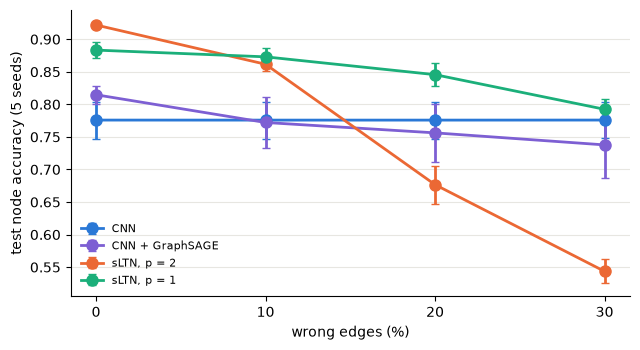

In [12]:
_, rows_w = load("wrong")
_, rows_s = load("soft")
rows_all = rows_w + rows_s
wrongs = [0.0, 0.1, 0.2, 0.3]
print(f"{'wrong edges':>11s}" + "".join(f"{NAMES.get(m, m):>18s}" for m in ("cnn", "gnn", "sltn", "sltn-p1", "sltn-w0.25")))
for w in wrongs:
    print(f"{w:>11.0%}" + "".join(f"{'%.3f ± %.3f' % ms(rows_all, wrong=w, model=m)[:2]:>18s}"
                                  for m in ("cnn", "gnn", "sltn", "sltn-p1", "sltn-w0.25")))
print("\nsLTN p = 2, accuracy on nodes touching a wrong edge / on the other nodes:")
for w in wrongs[1:]:
    a, o = ms(rows_w, "acc_wrong_nodes", wrong=w, model="sltn")[0], ms(rows_w, "acc_other_nodes", wrong=w, model="sltn")[0]
    print(f"  {w:.0%}: {a:.3f} / {o:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for m in ("cnn", "gnn", "sltn", "sltn-p1"):
    v = [ms(rows_all, wrong=w, model=m) for w in wrongs]
    ax.errorbar([100 * w for w in wrongs], [x[0] for x in v], yerr=[x[1] for x in v], color=MODEL_COLOURS[m],
                lw=2, marker="o", ms=8, capsize=3, label=NAMES[m] + (", p = 2" if m == "sltn" else ""))
ax.set_xticks([0, 10, 20, 30]); ax.set_xlabel("wrong edges (%)"); ax.set_ylabel("test node accuracy (5 seeds)")
ax.legend(fontsize=8, frameon=False, loc="lower left")
ax.grid(axis="y", color="#e7e6e1", lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

(`sltn-w0.25` in the table is a third way to soften the rule, tried in the 5-seed runs only: p = 2, with the rule's loss weighted by 0.25 against the labels.)

## 8. Findings

Seed 0 trained in this notebook; 5 seeds run beforehand on a T4 GPU (sLTN `857c7ac`; `124c1f8` for Section 7).

**1. One rule makes a few labels enough.**
- sLTN reaches 0.920–0.922 node accuracy at 1%, 2% and 5% labels (28 to 186 labelled nodes), with a std over seeds of at most 0.004. The CNN trained on all ~3,300 labels reaches 0.938.
- It beats the CNN and the GNN on every seed at every label fraction: by at least 17 and 12 points at 1% labels, 11 and 9 at 2%, 7 and 3 at 5%.
- **The number of labels barely matters** for sLTN, because the labels only break the colour symmetry; the baselines climb with them and vary 3–20 times more.

**2. The baseline sees the edges and still loses.** The GNN learns how to use the neighbours from the same few labels, and gains only 4–5 points over the CNN at 1–2%. sLTN's knowledge says how neighbours relate, with no data needed.

**3. With the default aggregator, wrong knowledge breaks sLTN sharply.** At 10% wrong edges sLTN (p = 2) still beats both baselines on every seed (0.862); at 20% it falls to 0.677, 10 points below the CNN that ignores the edges, and to 0.544 at 30%.
- **The damage is global:** nodes on a wrong edge and the other nodes lose the same accuracy, because the rule trains one shared CNN, which sees only the image. Wrong edges teach it wrong digit features for every node. (In the fever-ward example, `4_FeverWard`, the damage stayed on the wrong rule's own days, because the network could tell those days apart.)
- **The rule is almost the only supervision** here (60–80 labels against ~5,000 edges), so nothing outweighs it.

**4. The aggregator's p is a robustness knob.** With p = 1 the accuracy degrades gently, 0.883 → 0.873 → 0.846 → 0.792 from 0% to 30% wrong edges, and sLTN stays the best model on every seed up to 20% (at 30%: better than the GNN on 5/5 seeds, the CNN on 4/5). The price: 0.883 instead of 0.922 when the knowledge is exact. High p trusts the rule fully; p = 1 tolerates violations. Weighting the rule down instead is worse everywhere: it weakens the correct and the wrong edges alike.

**Limits:**
- **Synthetic graphs:** the exact rule is exactly how the graphs were made; wrong edges are the only source of wrong knowledge, and they are spread uniformly.
- **No test-time reasoning:** sLTN predicts each node alone, on purpose. Using the rule at test time (e.g. to correct the predictions on a graph) would likely raise the graphs fully right, and is left out.
- **One GNN family and fixed settings:** GraphSAGE-style, 1,500 steps, no tuning per model.